In [21]:
# Chargement des bibliothèques de base
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import joblib as jb

In [22]:
# Masquer les messages d'avertissement
import warnings
warnings.filterwarnings("ignore")

### <font color = 'teal'>Importer et Lire les données<font>

In [23]:
# Lecture du fichier CSV des téléphones
jeu_donnees = pd.read_csv("telephone_data.csv")

In [24]:
# Nombre de lignes et de colonnes
print(f"Dimension du dataset : {jeu_donnees.shape}")

Dimension du dataset : (3253, 7)


In [25]:
# Résumé des colonnes et de leurs types
print(f"Infos du dataset : {jeu_donnees.info()}")

<class 'pandas.DataFrame'>
RangeIndex: 3253 entries, 0 to 3252
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   prix      3253 non-null   int64  
 1   adresse   3253 non-null   str    
 2   marque    3253 non-null   str    
 3   dim_ecr   3253 non-null   float64
 4   ram       3253 non-null   int64  
 5   stockage  3253 non-null   int64  
 6   etat      3253 non-null   str    
dtypes: float64(1), int64(3), str(3)
memory usage: 252.6 KB
Infos du dataset : None


### <font color = 'teal'>Exploration et preparation des données<font>



###### <font color = 'bisque'> Selection des variables catégorielles et quantitatives

In [26]:
# Isoler les colonnes catégorielles et les décrire
donnees_categorielles = jeu_donnees.select_dtypes(exclude = 'number')
print(f"Variable categirielles :")
print(donnees_categorielles)
print(f"Description dees variables cetgorielle")
donnees_categorielles.describe()


Variable categirielles :
         adresse   marque        etat
0     Guediawaye   iPhone  D'occasion
1         Mermoz   iPhone  D'occasion
2         Médina   iPhone  D'occasion
3        Plateau  Samsung  D'occasion
4         Mermoz  Samsung  D'occasion
...          ...      ...         ...
3248      Médina   iPhone      Venant
3249      Pikine     Oppo      Venant
3250     Plateau   Xiaomi      Venant
3251    Dalifort   iPhone      Venant
3252      Médina   iPhone      Venant

[3253 rows x 3 columns]
Description dees variables cetgorielle


,adresse,marque,etat
count,3253,3253,3253
unique,43,28,4
top,Plateau,iPhone,Réconditionné
freq,415,1571,1053


In [27]:
# Isoler les colonnes numériques
donnees_numeriques = jeu_donnees.select_dtypes(include = 'number')
print(f"Variable quantitative :")
donnees_numeriques

Variable quantitative :


,prix,dim_ecr,ram,stockage
0,580000,6.0,8,128
1,250000,6.0,4,128
2,80000,5.0,5,128
3,290000,6.0,8,256
4,250000,6.0,8,256
...,...,...,...,...
3248,410000,6.0,12,128
3249,140000,6.0,88,128
3250,375000,6.0,16,512
3251,365000,6.0,6,128


###### <font color = 'bisque'> Exploration des variables catégorielles

In [28]:
# Fonction qui trace le diagramme en barres des effectifs d'une colonne
def tracer_diagramme_barres(nom_colonne, table_donnees=None):
    import nbformat
    import plotly.io._renderers as _r
    import plotly.express as px

    # Contournement : certains noyaux gardent en mémoire « nbformat absent » même après son installation
    if getattr(_r, "nbformat", None) is None:
        _r.nbformat = nbformat

    table_donnees = jeu_donnees if table_donnees is None else table_donnees

    effectifs = table_donnees[nom_colonne].value_counts().reset_index()
    effectifs.columns = ["category", "count"]
    effectifs["category"] = effectifs["category"].astype(str)

    graphique = px.bar(effectifs, x="category", y="count", color="category", text_auto=True, title=f"Distribution de {nom_colonne}",)
    graphique.update_layout(xaxis_title=nom_colonne, yaxis_title="Nombre d'occurrences", showlegend=False,)
    graphique.show()


In [29]:
for colonne in donnees_categorielles:
    tracer_diagramme_barres(colonne)

###### <font color = 'bisque'> Exploration des variables quantitatives

In [30]:
# Statistiques descriptives des colonnes numériques
print("Description des varaibles quantitatives")
donnees_numeriques.describe()

Description des varaibles quantitatives


,prix,dim_ecr,ram,stockage
count,3.253000e+03,3253.000000,3253.000000,3253.000000
mean,3.608303e+05,6.510913,16.377498,193.514294
std,2.158010e+05,3.466092,20.291301,169.625904
min,1.000000e+00,0.000000,1.000000,1.000000
25%,2.370430e+05,6.000000,11.000000,128.000000
50%,3.620430e+05,6.000000,12.000000,158.000000
75%,4.620440e+05,7.000000,14.000000,256.000000
max,3.335000e+06,75.000000,512.000000,5120.000000


In [31]:
# Diagramme en barres pour chaque colonne numérique
for colonne in donnees_numeriques:
    tracer_diagramme_barres(colonne)

In [32]:
# Fonction qui trace la boîte à moustaches d'une colonne
def tracer_boite_moustaches(colonne):
  plt.figure(figsize=(25,3))
  sns.boxplot(x=jeu_donnees[colonne])
  plt.show()

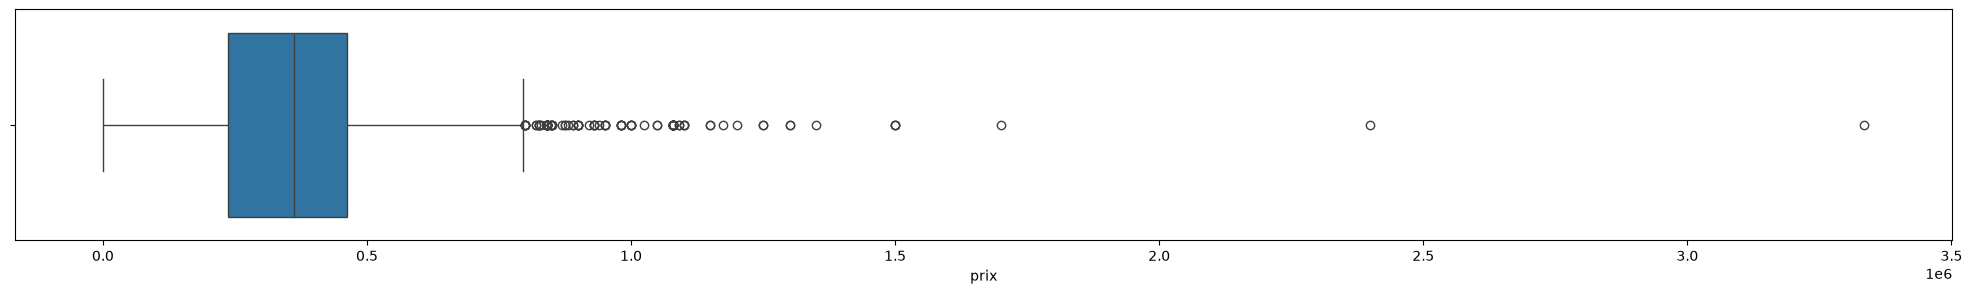

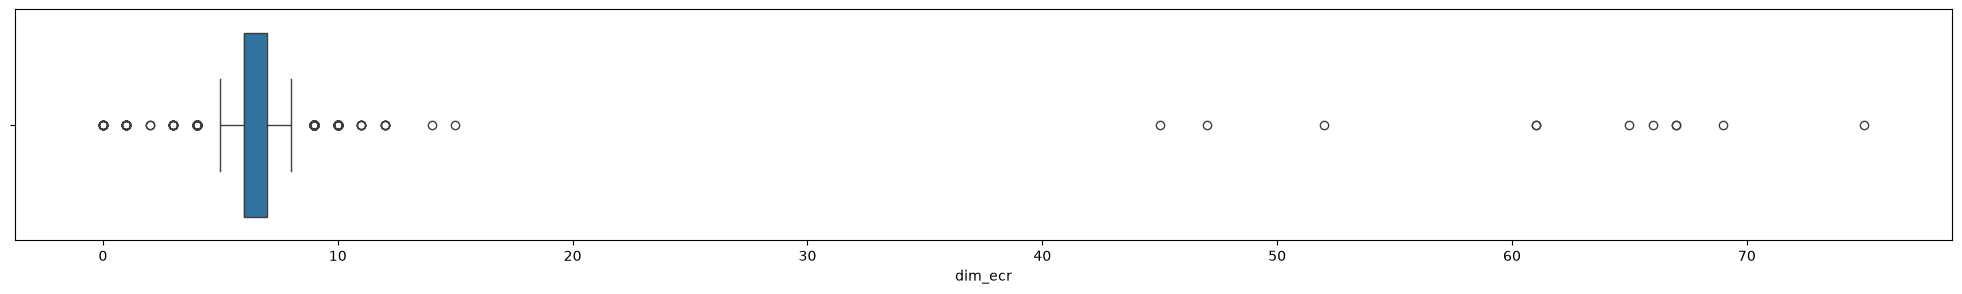

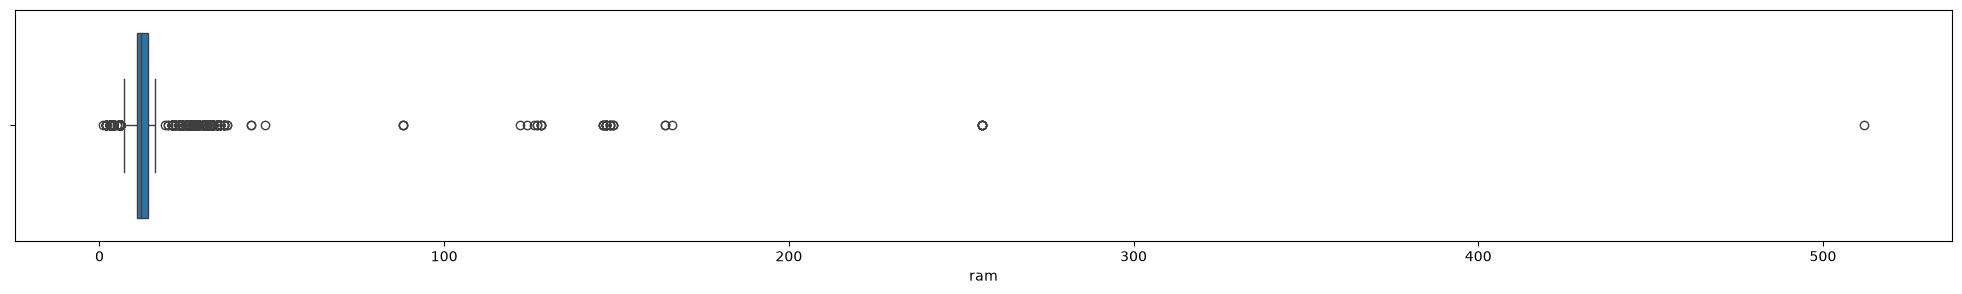

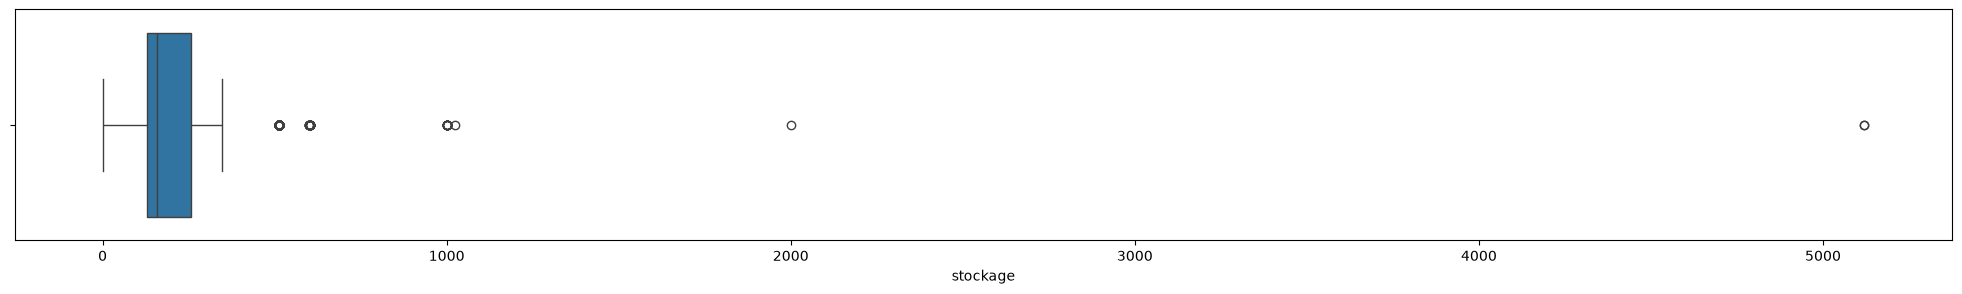

In [33]:
# Boîtes à moustaches des colonnes numériques
for colonne in donnees_numeriques:
    tracer_boite_moustaches(colonne)

###### <font color = 'bisque'> Preparation des données

In [34]:
# Contrôle des valeurs manquantes
jeu_donnees.isna().sum()

prix        0
adresse     0
marque      0
dim_ecr     0
ram         0
stockage    0
etat        0
dtype: int64

In [35]:
# Mémoriser les valeurs uniques de chaque variable catégorielle explicative
from pathlib import Path

valeurs_uniques_par_colonne = {colonne: np.unique(jeu_donnees[colonne]).tolist() for colonne in donnees_categorielles.columns if colonne != "etat"}
# Enregistrement sur disque
chemin_fichier = Path("./models/telephone_uniques.joblib")
chemin_fichier.parent.mkdir(parents=True, exist_ok=True)   # Crée le dossier ./models s'il n'existe pas
jb.dump(valeurs_uniques_par_colonne, chemin_fichier)

print("Enregistré dans :", chemin_fichier.resolve())
valeurs_uniques_par_colonne['marque']

Enregistré dans : /home/dashwood/Documents/ML/souane/models/telephone_uniques.joblib


['Alcatel',
 'Asus',
 'Atouch',
 'Autres',
 'BlackBerry',
 'Crosscall',
 'Google',
 'Honor',
 'Huawei',
 'Ice-Phone',
 'Infinix',
 'Itel',
 'LG',
 'Motorola',
 'Nodis',
 'Nokia',
 'OnePlus',
 'Oppo',
 'Panasonic',
 'Samsung',
 'Sharp',
 'Sony',
 'Tecno',
 'Viwa',
 'Xiaomi',
 'ZTE',
 'iPad',
 'iPhone']

In [36]:
# Encodage des variables catégorielles
from sklearn.preprocessing import LabelEncoder

encodeurs_par_colonne = {}
for colonne in donnees_categorielles.columns:
    encodeur_colonne = LabelEncoder()
    jeu_donnees[colonne] = encodeur_colonne.fit_transform(jeu_donnees[colonne])
    encodeurs_par_colonne[colonne] = encodeur_colonne

noms_classes = encodeurs_par_colonne['etat'].classes_
print(f"Classname : {noms_classes}")

Classname : ["D'occasion" 'Neuf' 'Réconditionné' 'Venant']


In [37]:
# Détection et traitement des valeurs aberrantes

from sklearn.impute import KNNImputer

def traiter_valeurs_aberrantes(jeu_donnees, colonne, n_neighbors=5):
    quartile_1 = jeu_donnees[colonne].quantile(0.25)
    quartile_3 = jeu_donnees[colonne].quantile(0.75)
    ecart_interquartile = quartile_3 - quartile_1
    borne_inferieure = quartile_1 - 1.5 * ecart_interquartile
    borne_superieure = quartile_3 + 1.5 * ecart_interquartile

    jeu_donnees.loc[(jeu_donnees[colonne] < borne_inferieure) | (jeu_donnees[colonne] > borne_superieure), colonne] = np.nan
    imputateur_knn = KNNImputer(n_neighbors=n_neighbors)
    jeu_donnees[:] = imputateur_knn.fit_transform(jeu_donnees)

In [38]:
for colonne in donnees_numeriques :
    traiter_valeurs_aberrantes(jeu_donnees,colonne)

In [39]:
# Séparer les variables explicatives de la variable cible
caracteristiques = jeu_donnees.drop('etat', axis = 1).values
cible = jeu_donnees.etat.values

noms_variables_explicatives = jeu_donnees.drop('etat', axis = 1).columns.tolist()
jb.dump(noms_variables_explicatives, "./models/telephone_features.joblib")
print(f"Les features : {noms_variables_explicatives}")

Les features : ['prix', 'adresse', 'marque', 'dim_ecr', 'ram', 'stockage']


In [40]:
# Découpage en entraînement, validation et test

from sklearn.model_selection import train_test_split
x_entrainement, x_validation_test, y_entrainement, y_validation_test = train_test_split(caracteristiques, cible, train_size = 0.8, random_state = 42)
x_validation, x_test, y_validation, y_test = train_test_split(x_validation_test, y_validation_test, train_size = 0.5, random_state = 42)

In [41]:
# Mise à l'échelle des données
from sklearn.preprocessing import MinMaxScaler # Z = (X - Xmin) / (Xmax - Xmin)
mise_a_echelle = MinMaxScaler()
x_entrainement = mise_a_echelle.fit_transform(x_entrainement)
x_validation = mise_a_echelle.transform(x_validation)
x_test = mise_a_echelle.transform(x_test)
x_entrainement[:5]

array([[0.54087993, 0.54761905, 0.22222222, 0.33333333, 0.55555556,
        0.36599424],
       [0.45539931, 0.64285714, 0.96296296, 0.        , 0.44444444,
        0.44956772],
       [0.29816893, 0.61904762, 0.96296296, 0.33333333, 0.44444444,
        0.26512968],
       [0.58118815, 0.42857143, 0.92592593, 0.66666667, 0.44444444,
        0.44956772],
       [0.29816641, 0.61904762, 0.96296296, 0.66666667, 0.44444444,
        0.26801153]])

In [42]:
# Enregistrement du normaliseur
jb.dump(mise_a_echelle, "./models/telephone_scaler.joblib")

['./models/telephone_scaler.joblib']

### <font color = 'teal'>Fonctions d'évaluation<font>

In [43]:
# Fonction d'évaluation sur les données de validation
from sklearn.metrics import f1_score, accuracy_score
def evaluer_modele(modele):
  y_predit = modele.predict(x_validation)
  exactitude = accuracy_score(y_validation, y_predit)
  score_f1 = f1_score(y_validation, y_predit, average='weighted')
  return exactitude, score_f1

In [44]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
def tracer_matrice_confusion(modele):

    y_predit = modele.predict(x_validation)
    matrice_confusion = confusion_matrix(y_validation, y_predit, labels=np.arange(len(noms_classes)))

    affichage = ConfusionMatrixDisplay(confusion_matrix=matrice_confusion, display_labels=noms_classes)

    affichage.plot()
    plt.title('Matrice de confusion')
    plt.show()

### <font color = 'teal'>Logistic Regression<font>

###### <font color = 'bisque'> Recherche des paramètre optimaux

In [45]:
# Recherche des meilleurs paramètres de la régression logistique
from sklearn.model_selection import GridSearchCV, KFold
from sklearn.linear_model import LogisticRegression
validation_croisee = KFold(n_splits = 5, shuffle =True, random_state= 42)
grille_reg_logistique = {"C":np.logspace(-3,3,10),"penalty": ['l1','l2']}
reg_logistique = LogisticRegression(solver = 'saga', max_iter = 2000)
recherche_reg_logistique = GridSearchCV(reg_logistique, grille_reg_logistique, cv = validation_croisee, n_jobs = -1)
recherche_reg_logistique.fit(x_entrainement, y_entrainement)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",LogisticRegre...solver='saga')
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'C': array([1.0000...00000000e+03]), 'penalty': ['l1', 'l2']}"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",KFold(n_split... shuffle=True)
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Control

In [46]:
print(f"Parametres optimaux : {recherche_reg_logistique.best_params_}")

Parametres optimaux : {'C': np.float64(0.46415888336127775), 'penalty': 'l1'}


###### <font color = 'bisque'> Entrainement du modèle

In [47]:
print(f"Récupérer le modèle optimal : {recherche_reg_logistique.best_estimator_}")

Récupérer le modèle optimal : LogisticRegression(C=np.float64(0.46415888336127775), max_iter=2000,
                   penalty='l1', solver='saga')


###### <font color = 'bisque'> Evaluation du modèle

In [48]:
# Exactitude (accuracy) et score F1 de la régression logistique
modele_reg_logistique = recherche_reg_logistique.best_estimator_
exactitude_reg_logistique ,f1_reg_logistique = evaluer_modele(modele_reg_logistique)
print(f"accuracy : {exactitude_reg_logistique} -------F1-Score : {f1_reg_logistique}")

accuracy : 0.6861538461538461 -------F1-Score : 0.669378266103785


In [49]:
# Affichage des métriques de la régression logistique
print(f"Matrice de confusion : {evaluer_modele(modele_reg_logistique)}")


Matrice de confusion : (0.6861538461538461, 0.669378266103785)


### <font color = 'teal'>Decision Tree<font>

###### <font color = 'bisque'> Recherche des paramètre optimaux

In [50]:
# Recherche des meilleurs hyperparamètres de l'arbre de décision
from sklearn.tree import DecisionTreeClassifier
validation_croisee = KFold(n_splits = 5, shuffle =True, random_state= 42)

grille_arbre = {'criterion':['gini','entropy'],'max_depth':np.arange(3,15)}
arbre = DecisionTreeClassifier(random_state = 42)
recherche_arbre = GridSearchCV(arbre, grille_arbre, cv = validation_croisee, n_jobs = -1)
recherche_arbre.fit(x_entrainement, y_entrainement)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",DecisionTreeC...ndom_state=42)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'criterion': ['gini', 'entropy'], 'max_depth': array([ 3, 4..., 12, 13, 14])}"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",KFold(n_split... shuffle=True)
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, 

In [51]:
print(F"Affichage des parametres optimaux : {recherche_arbre.best_params_}")

Affichage des parametres optimaux : {'criterion': 'gini', 'max_depth': np.int64(13)}


###### <font color = 'bisque'> Entrainement du modèle

In [52]:
# Récupérer le meilleur arbre de décision
modele_arbre = recherche_arbre.best_estimator_

###### <font color = 'bisque'> Evaluation du modèle

In [53]:
# Exactitude (accuracy) et score F1 de l'arbre de décision
exactitude_arbre ,f1_arbre = evaluer_modele(modele_arbre)
print(f"accuracy : {exactitude_arbre} -------F1-Score : {f1_arbre}")

accuracy : 0.8153846153846154 -------F1-Score : 0.8157835633192417


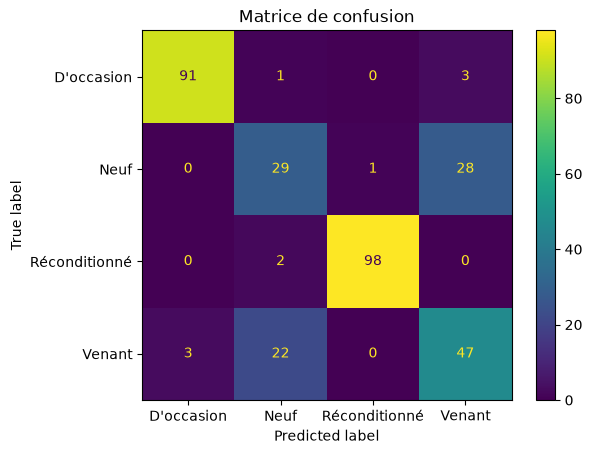

In [54]:
# Matrice de confusion sur la validation
tracer_matrice_confusion(modele_arbre)

### <font color = 'teal'>Random Forest<font>

In [55]:
# Recherche des meilleurs paramètres de la forêt aléatoire
from sklearn.ensemble import RandomForestClassifier
grille_foret = {
    'n_estimators': list(np.arange(10,100,10)),
    'max_depth' : list(np.arange(3,15)),
    'criterion' :['gini', 'entropy']
}
validation_croisee = KFold(n_splits = 5, shuffle =True, random_state= 42)

foret = RandomForestClassifier(random_state = 42)
recherche_foret = GridSearchCV(estimator=foret, param_grid=grille_foret, cv= validation_croisee, n_jobs = -1)
# Lancer l'entraînement
recherche_foret.fit(x_entrainement, y_entrainement)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestC...ndom_state=42)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'criterion': ['gini', 'entropy'], 'max_depth': [np.int64(3), np.int64(4), ...], 'n_estimators': [np.int64(10), np.int64(20), ...]}"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",KFold(n_split... shuffle=True)
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Suppo

In [56]:
print(f"Paramètres optimaux : {recherche_foret.best_params_}")

Paramètres optimaux : {'criterion': 'gini', 'max_depth': np.int64(11), 'n_estimators': np.int64(50)}


In [57]:
# Récupérer la meilleure forêt aléatoire
modele_foret = recherche_foret.best_estimator_

##### <font color ='bisque'>Evaluation du Random Forest<font>

In [58]:
exactitude_foret ,f1_foret = evaluer_modele(modele_foret)
print(f"accuracy : {exactitude_foret} -------F1-Score : {f1_foret}")

accuracy : 0.8738461538461538 -------F1-Score : 0.8733799137197632


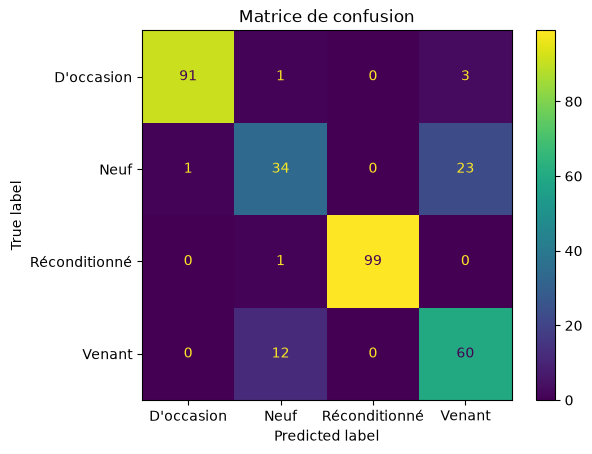

In [59]:
# Matrice de confusion sur la validation
tracer_matrice_confusion(modele_foret)

### <font color = 'teal'>Comparaison des modèles<font>

In [60]:
# Diagrammes comparant les performances
noms_modeles = ['LG', 'TREE','RF']
liste_exactitudes = [exactitude_reg_logistique, exactitude_arbre, exactitude_foret]
liste_f1 = [f1_reg_logistique,f1_arbre, f1_foret]
liste_resultats = [liste_exactitudes, liste_f1]

for indice in range(2):

    graphique = px.bar(y = noms_modeles, x = liste_resultats[indice], color = noms_modeles, text_auto = True)
    graphique.show()

### <font color = 'teal'>Sélection et sauvegarde du modèle le plus performant<font>

In [61]:
modeles = {'LG': modele_reg_logistique, 'TREE': modele_arbre, 'RF': modele_foret}
nom_meilleur_modele = noms_modeles[int(np.argmax(liste_exactitudes))]
meilleur_modele = modeles[nom_meilleur_modele]
print(f"Le plus performant : {nom_meilleur_modele} (accuracy = {max(liste_exactitudes):.4f})")

Le plus performant : RF (accuracy = 0.8738)


In [62]:
# Enregistrement du meilleur modèle
jb.dump(meilleur_modele, "./models/telephone_model.joblib")

['./models/telephone_model.joblib']

### <font color ='bisque'>Tester le modèle le plus performant<font>

In [63]:
# Évaluation sur les données de test du modèle jugé le plus performant
from sklearn.metrics import accuracy_score, classification_report

y_predit_test = meilleur_modele.predict(x_test)
print(f"accuracy (test) : {accuracy_score(y_test, y_predit_test):.4f}")
print(classification_report(
    y_test, y_predit_test,
    target_names=[str(nom_classe) for nom_classe in noms_classes],
))

accuracy (test) : 0.8957
               precision    recall  f1-score   support

   D'occasion       0.98      0.95      0.96        83
         Neuf       0.81      0.76      0.78        71
Réconditionné       1.00      1.00      1.00       106
       Venant       0.74      0.80      0.77        66

     accuracy                           0.90       326
    macro avg       0.88      0.88      0.88       326
 weighted avg       0.90      0.90      0.90       326



In [64]:
# Extrait des 10 premiers exemples de test
x_test_extrait = x_test[:10]
y_test_extrait = y_test[:10]

# Prédictions sur cet extrait
y_pred_extrait = meilleur_modele.predict(x_test_extrait)
libelles_predits = encodeurs_par_colonne['etat'].inverse_transform(y_pred_extrait)
libelles_reels = encodeurs_par_colonne['etat'].inverse_transform(y_test_extrait)

for indice in range(10):
    print(f"Prédiction {indice + 1} : {libelles_predits[indice]} -- Réel : {libelles_reels[indice]}")

Prédiction 1 : Venant -- Réel : Venant
Prédiction 2 : Neuf -- Réel : Neuf
Prédiction 3 : D'occasion -- Réel : D'occasion
Prédiction 4 : D'occasion -- Réel : D'occasion
Prédiction 5 : D'occasion -- Réel : D'occasion
Prédiction 6 : Réconditionné -- Réel : Réconditionné
Prédiction 7 : Venant -- Réel : Venant
Prédiction 8 : Neuf -- Réel : Venant
Prédiction 9 : Réconditionné -- Réel : Réconditionné
Prédiction 10 : Venant -- Réel : Venant
